# Store Sales Forecasting - Exploratory Data Analysis

This notebook explores the Kaggle Store Sales dataset and identifies patterns, trends, and potential predictive features for forecasting sales.

In [18]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = Path(r"C:\Users\NickK\OneDrive\Υπολογιστής\github\kaggle_store_sales_forecasting")
RAW_DIR = BASE_DIR / "data" / "raw"

# 1. Data Loading and Initial Inspection

In [19]:
train = pd.read_csv(RAW_DIR / "train.csv")
test = pd.read_csv(RAW_DIR / "test.csv")
stores = pd.read_csv(RAW_DIR / "stores.csv")
oil = pd.read_csv(RAW_DIR / "oil.csv")
holidays = pd.read_csv(RAW_DIR / "holidays_events.csv")
transactions = pd.read_csv(RAW_DIR / "transactions.csv")
sample_submission = pd.read_csv(RAW_DIR / "sample_submission.csv")

# 2. Dataset Overview

In [20]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)

train.head()

files = [
    "train.csv",
    "test.csv",
    "stores.csv",
    "oil.csv",
    "holidays_events.csv",
    "transactions.csv",
    "sample_submission.csv"
]

for file in files:
    df = pd.read_csv(RAW_DIR / file)
    print(f"{file}: {df.shape}")

train.head()
train.info()

train["date"] = pd.to_datetime(train["date"])

train.head()

print("Date range:")
print(train["date"].min())
print(train["date"].max())

print("Number of stores:")
print(train["store_nbr"].nunique())

print("\nNumber of product families:")
print(train["family"].nunique())

Train shape: (3000888, 6)
Test shape: (28512, 5)
train.csv: (3000888, 6)
test.csv: (28512, 5)
stores.csv: (54, 5)
oil.csv: (1218, 2)
holidays_events.csv: (350, 6)
transactions.csv: (83488, 3)
sample_submission.csv: (28512, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         object 
 2   store_nbr    int64  
 3   family       object 
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 137.4+ MB
Date range:
2013-01-01 00:00:00
2017-08-15 00:00:00
Number of stores:
54

Number of product families:
33


# 3. Target Variable Analysis

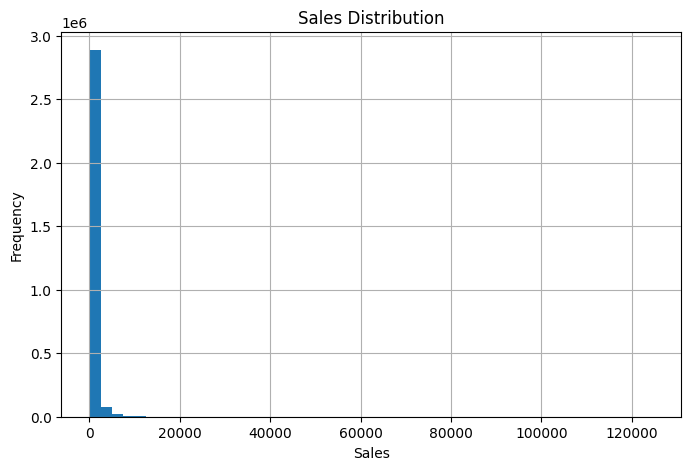

Zero sales records:
939130


In [21]:
train["sales"].describe()

plt.figure(figsize=(8,5))
train["sales"].hist(bins=50)
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

print("Zero sales records:")
print((train["sales"] == 0).sum())

# 4. Product Family Analysis

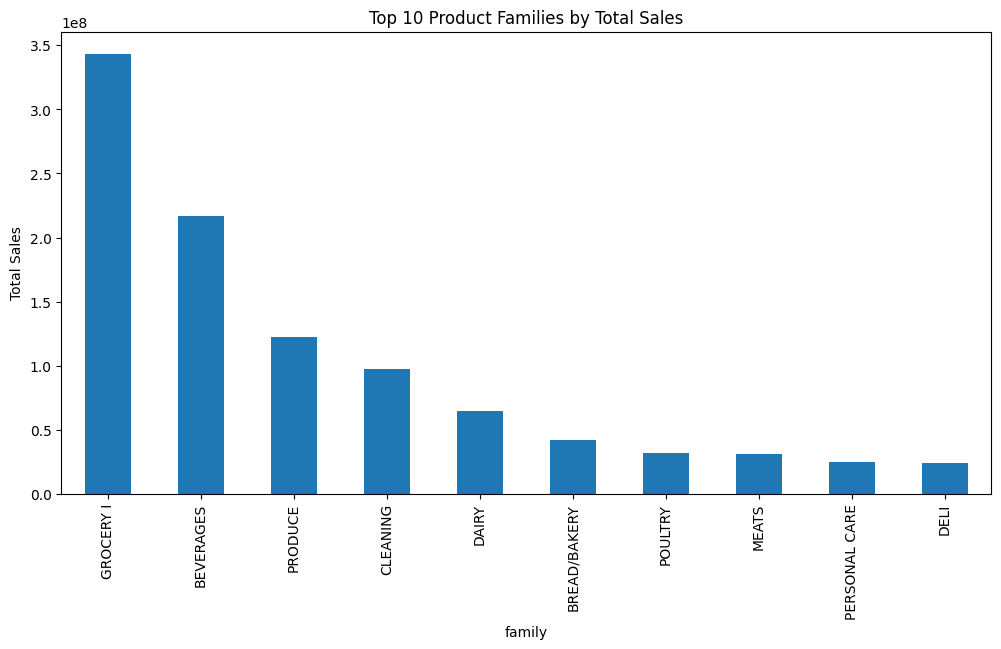

In [22]:
family_sales = (
    train.groupby("family")["sales"]
    .sum()
    .sort_values(ascending=False)
)

family_sales.head(10)

plt.figure(figsize=(12,6))
family_sales.head(10).plot(kind="bar")
plt.title("Top 10 Product Families by Total Sales")
plt.ylabel("Total Sales")
plt.show()

# 5. Store Analysis

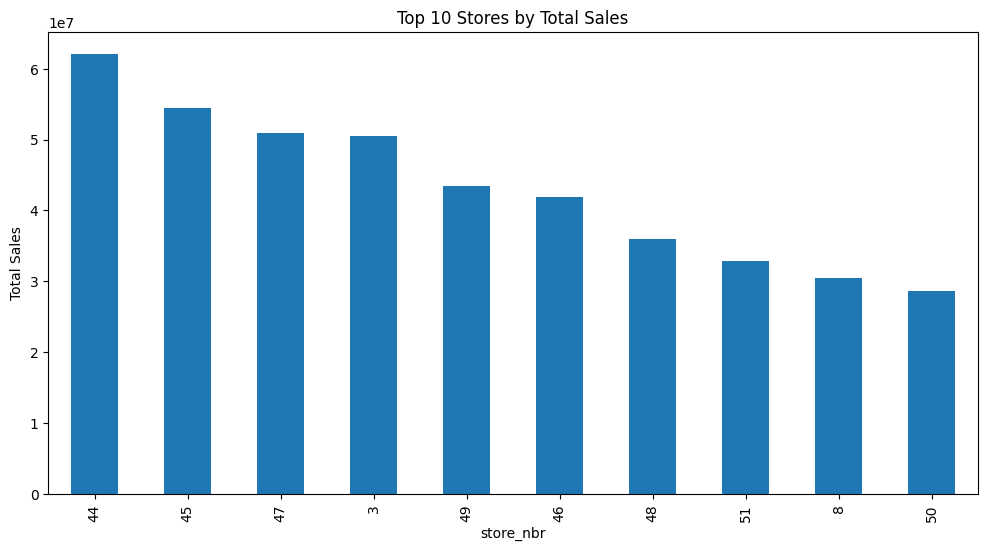

In [23]:
store_sales = (
    train.groupby("store_nbr")["sales"]
    .sum()
    .sort_values(ascending=False)
)

store_sales.head(10)

plt.figure(figsize=(12,6))
store_sales.head(10).plot(kind="bar")
plt.title("Top 10 Stores by Total Sales")
plt.ylabel("Total Sales")
plt.show()

# 6. Promotion Analysis

In [24]:
train.groupby(
    train["onpromotion"] > 0
)["sales"].mean()

onpromotion
False     158.246681
True     1137.693730
Name: sales, dtype: float64

# 7. Time Series Analysis

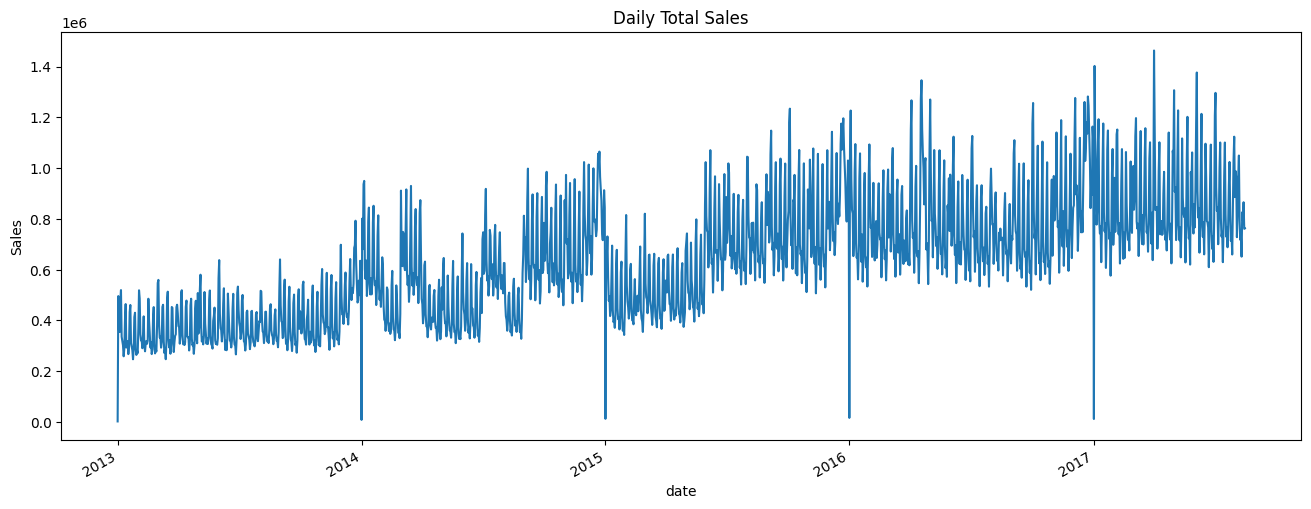

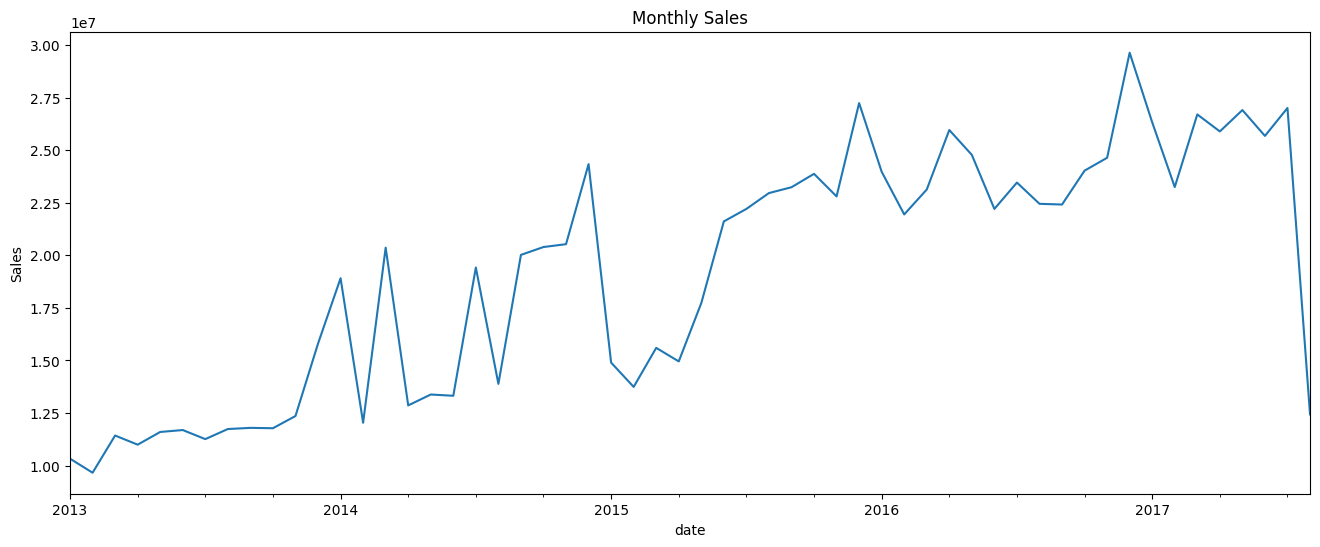

day_of_week
Sunday       463.085366
Saturday     433.336472
Monday       346.544732
Wednesday    332.909401
Friday       325.238138
Tuesday      319.823843
Thursday     283.540517
Name: sales, dtype: float64


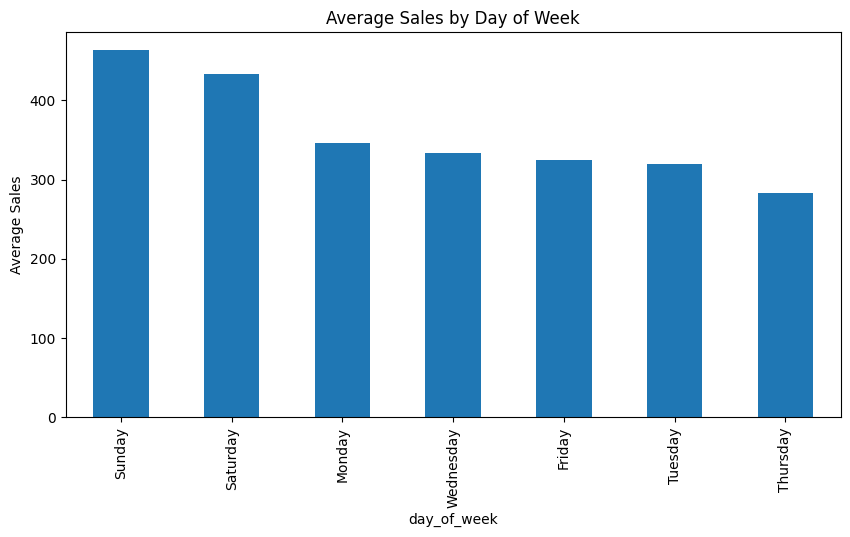

In [25]:
daily_sales = (
    train.groupby("date")["sales"]
    .sum()
)

daily_sales.head()

plt.figure(figsize=(16,6))
daily_sales.plot()
plt.title("Daily Total Sales")
plt.ylabel("Sales")
plt.show()

monthly_sales = (
    train.groupby(
        train["date"].dt.to_period("M")
    )["sales"]
    .sum()
)

monthly_sales.head()

plt.figure(figsize=(16,6))
monthly_sales.plot()
plt.title("Monthly Sales")
plt.ylabel("Sales")
plt.show()

train["day_of_week"] = train["date"].dt.day_name()

dow_sales = (
    train.groupby("day_of_week")["sales"]
    .mean()
    .sort_values(ascending=False)
)

print(dow_sales)

plt.figure(figsize=(10,5))
dow_sales.plot(kind="bar")
plt.title("Average Sales by Day of Week")
plt.ylabel("Average Sales")
plt.show()

# 8. Initial Feature Engineering Ideas

In [26]:
eda_features = train.copy()

eda_features["year"] = eda_features["date"].dt.year
eda_features["month"] = eda_features["date"].dt.month
eda_features["day"] = eda_features["date"].dt.day
eda_features["week"] = eda_features["date"].dt.isocalendar().week
eda_features["quarter"] = eda_features["date"].dt.quarter
eda_features["day_of_week"] = eda_features["date"].dt.day_name()

eda_features["is_weekend"] = (
    eda_features["date"].dt.dayofweek >= 5
)

eda_features.head()

,id,date,store_nbr,family,sales,onpromotion,day_of_week,year,month,day,week,quarter,is_weekend
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,Tuesday,2013,1,1,1,1,False
1,1,2013-01-01,1,BABY CARE,0.0,0,Tuesday,2013,1,1,1,1,False
2,2,2013-01-01,1,BEAUTY,0.0,0,Tuesday,2013,1,1,1,1,False
3,3,2013-01-01,1,BEVERAGES,0.0,0,Tuesday,2013,1,1,1,1,False
4,4,2013-01-01,1,BOOKS,0.0,0,Tuesday,2013,1,1,1,1,False


# 9. Holiday Analysis

In [27]:
holidays.head(20)

print("Holiday Types:")
print(holidays["type"].value_counts())

print("\nLocales:")
print(holidays["locale"].value_counts())

daily_sales = (
    train.groupby("date")["sales"]
    .sum()
    .reset_index()
)

daily_sales["date"] = pd.to_datetime(
    daily_sales["date"]
)

Holiday Types:
type
Holiday       221
Event          56
Additional     51
Transfer       12
Bridge          5
Work Day        5
Name: count, dtype: int64

Locales:
locale
National    174
Local       152
Regional     24
Name: count, dtype: int64


# 10. Earthquake Impact Analysis

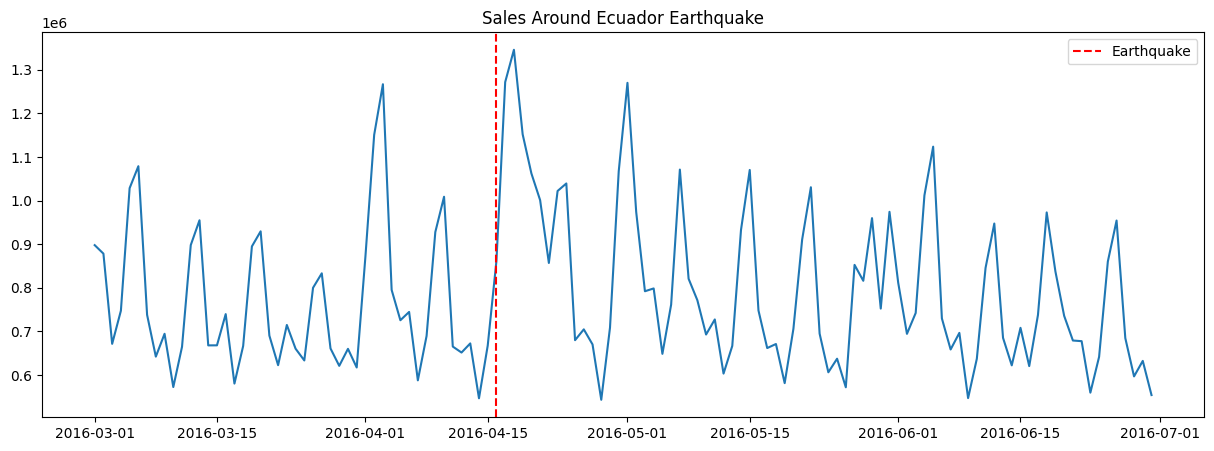

In [28]:
earthquake_window = daily_sales[
    (daily_sales["date"] >= "2016-03-01") &
    (daily_sales["date"] <= "2016-06-30")
]

earthquake_window.head()

plt.figure(figsize=(15,5))

plt.plot(
    earthquake_window["date"],
    earthquake_window["sales"]
)

plt.axvline(
    pd.Timestamp("2016-04-16"),
    color="red",
    linestyle="--",
    label="Earthquake"
)

plt.legend()
plt.title("Sales Around Ecuador Earthquake")
plt.show()

# Conclusions

Key findings:

- Sales are highly skewed.
- Promotions strongly increase sales.
- Weekend sales are significantly higher.
- Product family has a major impact on sales.
- Store-specific effects are important.
- Long-term growth trend exists.
- The earthquake appears to influence sales patterns.

Potential predictive features:

- year
- month
- week
- day_of_week
- is_weekend
- onpromotion
- store_nbr
- family
- holiday indicators
- earthquake-related indicators

In [29]:
print("""
EDA Conclusions

1. Sales are highly right-skewed.
2. Approximately 31% of observations have zero sales.
3. Promotions strongly increase sales.
4. Weekend sales are higher than weekday sales.
5. Significant differences exist among stores.
6. Significant differences exist among product families.
7. Long-term sales growth is observed from 2013 to 2017.
8. The earthquake appears to affect sales patterns.
""")


EDA Conclusions

1. Sales are highly right-skewed.
2. Approximately 31% of observations have zero sales.
3. Promotions strongly increase sales.
4. Weekend sales are higher than weekday sales.
5. Significant differences exist among stores.
6. Significant differences exist among product families.
7. Long-term sales growth is observed from 2013 to 2017.
8. The earthquake appears to affect sales patterns.

